# CS04: Hierarchical segment profiling (Olist)

Snapshot date: 2018-01-01. Ward linkage runs on a 5,000-customer sample (it needs O(n²) memory).
Every customer is then labeled by the nearest Ward centroid, and a depth-3 decision tree
turns the labels into rules that a non-technical reviewer can read.

In [1]:
import sys
from pathlib import Path

sys.path.insert(0, str(Path.cwd().parent / "src"))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from scipy.cluster.hierarchy import dendrogram

from hierseg.core import (
    FEATURES,
    RANDOM_STATE,
    SNAPSHOT_DATE,
    build_customer_features,
    choose_k,
    data_dir,
    load_tables,
    nearest_centroid_labels,
    scale_features,
    surrogate_tree,
    ward_labels,
)

FIG = Path.cwd().parent / "reports" / "figures"
FIG.mkdir(parents=True, exist_ok=True)

In [2]:
tables = load_tables()
print("data:", data_dir())
feats = build_customer_features(tables, SNAPSHOT_DATE)
print("customers:", len(feats))
print("share with exactly one order before snapshot:", round((feats["frequency"] == 1).mean(), 3))
feats.describe().round(2)

data: /home/patotricks15/.local/share/clv-data/olist


customers: 43315
share with exactly one order before snapshot: 0.972


,recency_days,frequency,monetary,avg_item_price,avg_freight,avg_review_score,avg_delivery_days
count,43315.00,43315.00,43315.00,43315.00,43315.00,43315.00,43315.00
mean,139.05,1.03,164.92,126.57,19.60,4.19,11.67
std,98.57,0.20,233.03,193.67,14.27,1.26,8.26
min,0.00,1.00,0.00,1.51,0.00,1.00,0.00
25%,47.00,1.00,62.99,42.90,13.51,4.00,7.00
50%,123.00,1.00,106.17,79.00,16.11,5.00,10.00
75%,215.00,1.00,181.41,139.90,20.12,5.00,14.00
max,483.00,9.00,13664.08,6735.00,314.40,5.00,209.00


In [3]:
X = scale_features(feats)
sample_idx = np.random.default_rng(RANDOM_STATE).choice(len(X), size=5000, replace=False)
X_sample = X[sample_idx]

k_table = choose_k(X_sample, k_range=range(3, 7))
k_table.round(3)

,k,silhouette,min_share
0,3,0.271,0.165
1,4,0.153,0.165
2,5,0.160,0.036
3,6,0.170,0.036


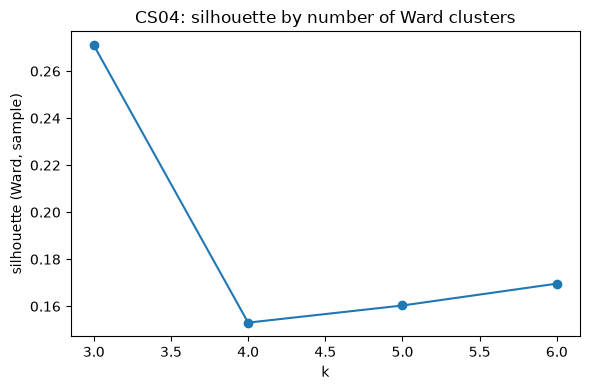

In [4]:
fig, ax = plt.subplots(figsize=(6, 4))
ax.plot(k_table["k"], k_table["silhouette"], marker="o")
ax.set_xlabel("k")
ax.set_ylabel("silhouette (Ward, sample)")
ax.set_title("CS04: silhouette by number of Ward clusters")
fig.tight_layout()
fig.savefig(FIG / "cs04_silhouette_by_k.png", dpi=150)
plt.show()

chosen k: 3


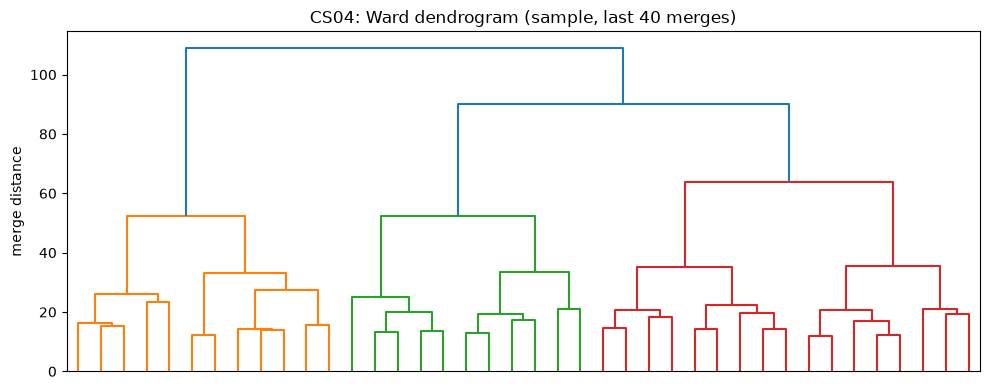

In [5]:
K = int(k_table.loc[k_table["silhouette"].idxmax(), "k"])
print("chosen k:", K)
labels_sample, Z = ward_labels(X_sample, K)

fig, ax = plt.subplots(figsize=(10, 4))
dendrogram(Z, truncate_mode="lastp", p=40, ax=ax, no_labels=True, color_threshold=Z[-(K - 1), 2])
ax.set_title("CS04: Ward dendrogram (sample, last 40 merges)")
ax.set_ylabel("merge distance")
fig.tight_layout()
fig.savefig(FIG / "cs04_dendrogram.png", dpi=150)
plt.show()

In [6]:
labels_all = nearest_centroid_labels(X_sample, labels_sample, X)
feats = feats.assign(segment=labels_all)
shares = feats["segment"].value_counts(normalize=True).sort_index()
print("share by segment:")
print(shares.round(3))
print("smallest segment share:", round(shares.min(), 4), "(minimum is 0.02)")

share by segment:
segment
1    0.168
2    0.212
3    0.620
Name: proportion, dtype: float64
smallest segment share: 0.1679 (minimum is 0.02)


In [7]:
profile = feats.groupby("segment").agg(
    customers=("frequency", "size"),
    median_recency_days=("recency_days", "median"),
    median_frequency=("frequency", "median"),
    median_monetary=("monetary", "median"),
    median_avg_item_price=("avg_item_price", "median"),
    median_review=("avg_review_score", "median"),
    median_delivery_days=("avg_delivery_days", "median"),
)
profile["share"] = profile["customers"] / profile["customers"].sum()
profile.round(2)

,customers,median_recency_days,median_frequency,median_monetary,median_avg_item_price,median_review,median_delivery_days,share
segment,,,,,,,,
1,7274,131.0,1.0,104.84,69.9,1.0,11.0,0.17
2,9166,122.0,1.0,208.72,159.0,5.0,14.0,0.21
3,26875,123.0,1.0,84.42,59.9,5.0,9.0,0.62


In [8]:
# Trees do not depend on monotone scaling, so the surrogate is fitted on raw values to keep thresholds readable.
tree, test_acc, rules = surrogate_tree(feats[FEATURES].to_numpy(), labels_all, FEATURES, max_depth=3)
print(f"held-out surrogate accuracy: {test_acc:.3f}")
print(rules)

held-out surrogate accuracy: 0.918
|--- avg_review_score <= 3.12
|   |--- avg_freight <= 26.06
|   |   |--- avg_delivery_days <= 6.25
|   |   |   |--- class: 1
|   |   |--- avg_delivery_days >  6.25
|   |   |   |--- class: 1
|   |--- avg_freight >  26.06
|   |   |--- avg_review_score <= 2.25
|   |   |   |--- class: 1
|   |   |--- avg_review_score >  2.25
|   |   |   |--- class: 2
|--- avg_review_score >  3.12
|   |--- avg_freight <= 21.27
|   |   |--- avg_delivery_days <= 18.25
|   |   |   |--- class: 3
|   |   |--- avg_delivery_days >  18.25
|   |   |   |--- class: 3
|   |--- avg_freight >  21.27
|   |   |--- avg_freight <= 25.76
|   |   |   |--- class: 2
|   |   |--- avg_freight >  25.76
|   |   |   |--- class: 2



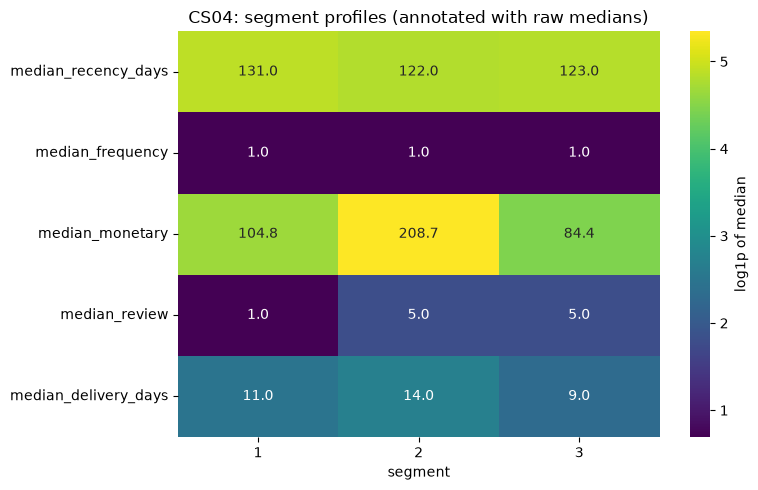

In [9]:
fig, ax = plt.subplots(figsize=(8, 5))
heat = profile[["median_recency_days", "median_frequency", "median_monetary", "median_review", "median_delivery_days"]]
sns.heatmap(
    np.log1p(heat.T.clip(lower=0)),
    annot=heat.T.round(1).values,
    fmt="",
    cmap="viridis",
    cbar_kws={"label": "log1p of median"},
    ax=ax,
)
ax.set_xlabel("segment")
ax.set_title("CS04: segment profiles (annotated with raw medians)")
fig.tight_layout()
fig.savefig(FIG / "cs04_profile_heatmap.png", dpi=150)
plt.show()